# Hands-on 11: Generator Data Getaran Mesin dengan Fault Injection

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 4.

Sinyal getaran sintetis motor01 (3000 sampel): normal, lalu fault injection berupa
amplitudo naik (1000-2000), noise bertambah (1500-2300), dan spike sesaat (1800-2500).
Output: `data/synthetic/vibration_fault_injection.csv` dengan `status_label`.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Sinyal Getaran + Fault Injection

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_vibration_fault.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset getaran disimpan ke: data/synthetic/vibration_fault_injection.csv (3000 baris)
   sample_id machine_id  vibration status_label
0          0    motor01    0.00010       normal
1          1    motor01    0.17380       normal
2          2    motor01    0.27257       normal
3          3    motor01    0.35741       normal
4          4    motor01    0.51126       normal

[INFO] Sekitar awal fault (sample 995-1005):
      sample_id machine_id  vibration status_label
995         995    motor01   -0.71925       normal
996         996    motor01   -0.46540       normal
997         997    motor01   -0.46069       normal
998         998    motor01   -0.25750       normal
999         999    motor01   -0.21594       normal
1000       1000    motor01    0.02870        fault
1001       1001    motor01    0.34988        fault
1002       1002    motor01    0.59216        fault
1003       1003    motor01    1.07258        fault
1004       1004    motor01    1.19341        fault

[INFO] S

## 2. Visualisasi

[SUKSES] outputs/figures/vibration_fault.png
[SUKSES] outputs/figures/vibration_fault_zoom.png



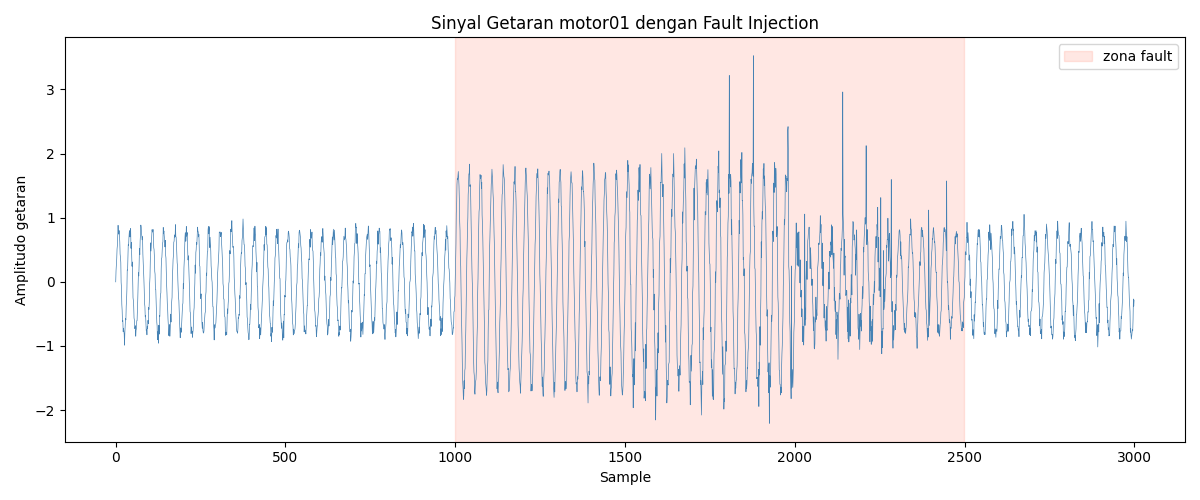

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_vibration_fault.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/vibration_fault.png")

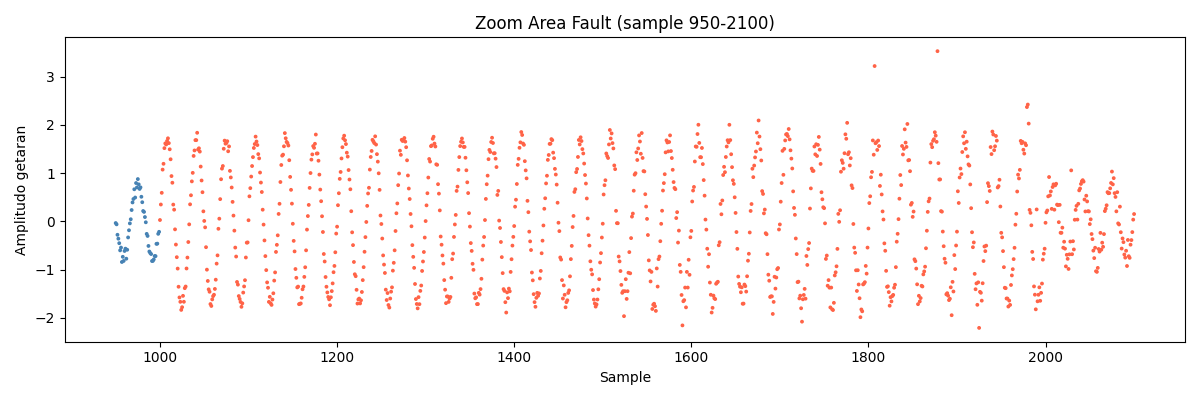

In [4]:
Image("outputs/figures/vibration_fault_zoom.png")

## Penutup

Zona fault terlihat jelas: amplitudo membesar, noise naik, dan spike muncul. Dataset
berlabel ini menjadi bahan Hands-on 15 (fitur getaran RMS/peak/kurtosis) dan Hands-on 36
(predictive maintenance).